# 5 - Support Vector Regression



### Import the tools and shared code

In [1]:
from pathlib import Path
import sys
import json
import hashlib
import platform
import cProfile
import pstats
import io
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import joblib
from sklearn.linear_model import LinearRegression
from IPython.display import display

project_root = Path("..").resolve()
for filename in ["evaluation.py", "features.py", "svr_model.py"]:
    assert (project_root / "src" / filename).is_file(), f"Missing src/{filename}. Check file placement."
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.evaluation import persistence_predict, regression_metrics
from src.features import make_features, INPUT_COLUMNS
from src.svr_model import build_svr_model

print("Project root:", project_root)
print("Python:", platform.python_version(), "| scikit-learn:", sklearn.__version__)

Project root: C:\Users\chris\OneDrive\Desktop\MMA3001\Project\mma3001_project
Python: 3.14.6 | scikit-learn: 1.9.1


### Load only training and validation data

In [2]:
space_prefix = "227f1068"
data_folder = project_root / "data" / "prepared" / space_prefix
with open(data_folder / "preparation_settings.json", encoding="utf-8") as file:
    settings = json.load(file)

feature_columns = settings["feature_columns"]
target_column = settings["target_column"]
assert feature_columns == INPUT_COLUMNS
assert target_column == "target_headcount"
assert settings["space_id"].startswith(space_prefix)
assert settings["horizon_minutes"] == 30

train = pd.read_csv(data_folder / "train.csv")
validation = pd.read_csv(data_folder / "validation.csv")
datasets = {"train": train, "validation": validation}
periods = {
    "train": (settings["train_start"], settings["validation_start"]),
    "validation": (settings["validation_start"], settings["test_start"])
}
fingerprints = {}

for name, dataset in datasets.items():
    for column in settings["timestamp_columns"]:
        dataset[column] = pd.to_datetime(dataset[column], utc=True)
    start, end = periods[name]
    assert len(dataset) == settings["split_counts"][name] and len(dataset) > 0
    assert dataset["forecast_time"].is_unique
    assert dataset["forecast_time"].is_monotonic_increasing
    assert np.isfinite(dataset[feature_columns + [target_column]].to_numpy(dtype=float)).all()
    assert (dataset["forecast_time"] >= pd.Timestamp(start)).all()
    assert (dataset["target_time"] < pd.Timestamp(end)).all()
    assert ((dataset["target_time"] - dataset["forecast_time"]) == pd.Timedelta(minutes=30)).all()
    assert (dataset["target_headcount_observed_at"] > dataset["forecast_time"]).all()
    assert (dataset[target_column] >= 0).all() and (dataset[target_column] % 1 == 0).all()
    fingerprints[name] = hashlib.sha256((data_folder / f"{name}.csv").read_bytes()).hexdigest()
    print(f"{name}: {len(dataset):,} examples checked")

for previous_model in ["persistence", "linear_regression"]:
    record = project_root / "outputs" / space_prefix / previous_model / "run_information.json"
    if record.is_file():
        with open(record, encoding="utf-8") as file:
            previous = json.load(file)
        assert previous["csv_sha256"] == fingerprints, "Data changed: investigate before comparing saved runs."
        if previous_model == "linear_regression":
            encoding_hash = hashlib.sha256((project_root / "src" / "features.py").read_bytes()).hexdigest()
            assert previous["encoding_source_sha256"] == encoding_hash, "Feature code changed: rerun Notebook 4 first."
        print("Data matches saved", previous_model, "run.")

assert train["target_time"].max() < validation["forecast_time"].min()
print("Only training and validation files have been loaded.")

train: 14,772 examples checked
validation: 3,388 examples checked
Data matches saved persistence run.
Data matches saved linear_regression run.
Only training and validation files have been loaded.


### Use the same inputs as linear regression


In [3]:
X_train = make_features(train)
X_validation = make_features(validation)
y_train = train[target_column].to_numpy(dtype=float)
y_validation = validation[target_column].to_numpy(dtype=float)
encoded_by_split = {"train": X_train, "validation": X_validation}

assert X_train.index.equals(train.index)
assert X_validation.index.equals(validation.index)
assert list(X_train.columns) == list(X_validation.columns)
assert target_column not in X_train.columns
print("Training inputs:", X_train.shape)
print("Validation inputs:", X_validation.shape)
display(X_train.head())

Training inputs: (14772, 11)
Validation inputs: (3388, 11)


,headcount_now,headcount_lag15,headcount_lag30,time_sin,time_cos,is_tuesday,is_wednesday,is_thursday,is_friday,is_saturday,is_sunday
0,1.0,1.0,1.0,-0.866025,-0.500000,0.0,0.0,0.0,0.0,0.0,1.0
1,1.0,0.0,1.0,-0.965926,-0.258819,0.0,0.0,0.0,0.0,0.0,1.0
2,0.0,0.0,1.0,-0.991445,-0.130526,0.0,0.0,0.0,0.0,0.0,1.0
3,1.0,0.0,1.0,0.707107,-0.707107,0.0,0.0,0.0,0.0,0.0,0.0
4,1.0,1.0,0.0,0.659346,-0.751840,0.0,0.0,0.0,0.0,0.0,0.0


### Declare the small parameter search before fitting

We try three penalty strengths (`C`), two tube widths (`epsilon`, in people), and two kernel locality settings (`gamma`): **12 candidates**. All use every training row and are scored on the same validation rows. There is no random split or hidden subsampling.

The reference starting SVR is `C=1`, `epsilon=0.1`, `gamma=0.1`. It is included in the search so we can compare the starting choice with the validation-selected choice.

**Selection rule:** lowest validation MAE; if exactly tied, lowest validation RMSE; if still tied, lowest candidate ID. Runtime is reported but not used as an unstable tie breaker. This bounded search explores settings; it does not establish a global optimum. Its selected validation score is a development result, not an independent final test score.


In [4]:
C_values = [0.1, 1.0, 10.0]
epsilon_values = [0.1, 0.5]
gamma_values = [0.01, 0.1]
initial_parameters = {"C": 1.0, "epsilon": 0.1, "gamma": 0.1}

candidates = []
for C in C_values:
    for epsilon in epsilon_values:
        for gamma in gamma_values:
            candidates.append({
                "candidate_id": len(candidates) + 1,
                "C": C, "epsilon": epsilon, "gamma": gamma
            })

print("Candidates to fit:", len(candidates))
display(pd.DataFrame(candidates))

Candidates to fit: 12


,candidate_id,C,epsilon,gamma
0,1,0.1,0.1,0.01
1,2,0.1,0.1,0.10
2,3,0.1,0.5,0.01
3,4,0.1,0.5,0.10
4,5,1.0,0.1,0.01
5,6,1.0,0.1,0.10
6,7,1.0,0.5,0.01
7,8,1.0,0.5,0.10
8,9,10.0,0.1,0.01
9,10,10.0,0.1,0.10


### Fit each candidate on training data and score validation forecasts


In [5]:
search_rows = []
fitted_models = {}
search_started = perf_counter()

for candidate in candidates:
    candidate_id = candidate["candidate_id"]
    candidate_model = build_svr_model(
        C=candidate["C"], epsilon=candidate["epsilon"], gamma=candidate["gamma"]
    )
    started = perf_counter()
    candidate_model.fit(X_train, y_train)
    fit_seconds = perf_counter() - started
    estimator = candidate_model.named_steps["svr"]
    assert estimator.fit_status_ == 0, "SVR did not converge; investigate before continuing."

    started = perf_counter()
    candidate_predictions = candidate_model.predict(X_validation)
    validation_predict_seconds = perf_counter() - started
    scores = regression_metrics(y_validation, candidate_predictions)

    search_rows.append({
        **candidate,
        "validation_mae_people": scores["mae"],
        "validation_rmse_people": scores["rmse"],
        "fit_seconds": fit_seconds,
        "validation_predict_seconds": validation_predict_seconds,
        "support_vectors": int(estimator.n_support_.sum()),
        "solver_iterations": int(estimator.n_iter_),
        "fit_status": int(estimator.fit_status_)
    })
    fitted_models[candidate_id] = candidate_model
    print(f"{candidate_id}/{len(candidates)}: C={candidate['C']}, "
          f"epsilon={candidate['epsilon']}, gamma={candidate['gamma']} | "
          f"validation MAE={scores['mae']:.4f}, RMSE={scores['rmse']:.4f} | "
          f"fit={fit_seconds:.2f}s", flush=True)

search_seconds = perf_counter() - search_started
search_results = pd.DataFrame(search_rows)
print("Parameter search finished. No model has used final-test data.")

1/12: C=0.1, epsilon=0.1, gamma=0.01 | validation MAE=0.7876, RMSE=1.1508 | fit=5.02s
2/12: C=0.1, epsilon=0.1, gamma=0.1 | validation MAE=0.7935, RMSE=1.1649 | fit=5.27s
3/12: C=0.1, epsilon=0.5, gamma=0.01 | validation MAE=0.7875, RMSE=1.1482 | fit=4.89s
4/12: C=0.1, epsilon=0.5, gamma=0.1 | validation MAE=0.8180, RMSE=1.1699 | fit=3.03s
5/12: C=1.0, epsilon=0.1, gamma=0.01 | validation MAE=0.7843, RMSE=1.1573 | fit=7.06s
6/12: C=1.0, epsilon=0.1, gamma=0.1 | validation MAE=0.7884, RMSE=1.1738 | fit=5.56s
7/12: C=1.0, epsilon=0.5, gamma=0.01 | validation MAE=0.7912, RMSE=1.1548 | fit=3.71s
8/12: C=1.0, epsilon=0.5, gamma=0.1 | validation MAE=0.8196, RMSE=1.1730 | fit=3.62s
9/12: C=10.0, epsilon=0.1, gamma=0.01 | validation MAE=0.7815, RMSE=1.1628 | fit=7.74s
10/12: C=10.0, epsilon=0.1, gamma=0.1 | validation MAE=0.7912, RMSE=1.1871 | fit=9.41s
11/12: C=10.0, epsilon=0.5, gamma=0.01 | validation MAE=0.8054, RMSE=1.1652 | fit=4.42s
12/12: C=10.0, epsilon=0.5, gamma=0.1 | validation MAE

### Select the SVR settings and verify training-only scaling

In [6]:
ranked_results = search_results.sort_values(
    ["validation_mae_people", "validation_rmse_people", "candidate_id"]
).reset_index(drop=True)
best_row = ranked_results.iloc[0]
best_id = int(best_row["candidate_id"])
model = fitted_models[best_id]
selected_parameters = {key: float(best_row[key]) for key in ["C", "epsilon", "gamma"]}

initial_mask = pd.Series(True, index=search_results.index)
for key, value in initial_parameters.items():
    initial_mask = initial_mask & (search_results[key] == value)
initial_row = search_results.loc[initial_mask].iloc[0]

scaler = model.named_steps["scaler"]
np.testing.assert_allclose(scaler.mean_, X_train.mean().to_numpy(), atol=1e-12)
np.testing.assert_allclose(scaler.var_, X_train.var(ddof=0).to_numpy(), atol=1e-12)
assert scaler.n_samples_seen_ == len(train)
scaling_summary = pd.DataFrame({
    "encoded_input": X_train.columns,
    "training_mean": scaler.mean_,
    "training_standard_deviation": np.sqrt(scaler.var_),
    "scale_used": scaler.scale_
})

print("Selected settings:", selected_parameters)
print("Initial SVR validation MAE:", float(initial_row["validation_mae_people"]))
print("Selected SVR validation MAE:", float(best_row["validation_mae_people"]))
display(ranked_results.round(4))
display(scaling_summary.round(4))

Selected settings: {'C': 10.0, 'epsilon': 0.1, 'gamma': 0.01}
Initial SVR validation MAE: 0.7884400938422249
Selected SVR validation MAE: 0.7814842904121425


,candidate_id,C,epsilon,gamma,validation_mae_people,validation_rmse_people,fit_seconds,validation_predict_seconds,support_vectors,solver_iterations,fit_status
0,9,10.0,0.1,0.01,0.7815,1.1628,7.7359,2.7485,13542,15863,0
1,5,1.0,0.1,0.01,0.7843,1.1573,7.0598,1.8165,13678,8260,0
2,3,0.1,0.5,0.01,0.7875,1.1482,4.8890,1.8158,9121,5266,0
3,1,0.1,0.1,0.01,0.7876,1.1508,5.0233,3.2232,13714,7598,0
4,6,1.0,0.1,0.10,0.7884,1.1738,5.5646,2.9062,13225,10515,0
5,10,10.0,0.1,0.10,0.7912,1.1871,9.4061,1.9466,13065,49220,0
6,7,1.0,0.5,0.01,0.7912,1.1548,3.7079,1.1898,9078,5867,0
7,2,0.1,0.1,0.10,0.7935,1.1649,5.2705,1.7372,13437,7780,0
8,11,10.0,0.5,0.01,0.8054,1.1652,4.4239,2.1352,9103,13750,0
9,4,0.1,0.5,0.10,0.8180,1.1699,3.0257,1.2185,9163,5890,0


,encoded_input,training_mean,training_standard_deviation,scale_used
0,headcount_now,1.9443,2.4573,2.4573
1,headcount_lag15,1.9580,2.4630,2.4630
2,headcount_lag30,1.9280,2.4472,2.4472
3,time_sin,-0.2431,0.6429,0.6429
4,time_cos,-0.2990,0.6619,0.6619
5,is_tuesday,0.1711,0.3766,0.3766
6,is_wednesday,0.1623,0.3687,0.3687
7,is_thursday,0.1909,0.3930,0.3930
8,is_friday,0.1474,0.3545,0.3545
9,is_saturday,0.0816,0.2738,0.2738


### Compare persistence, linear regression and selected SVR

In [7]:
linear_model = LinearRegression()
linear_started = perf_counter()
linear_model.fit(X_train, y_train)
linear_fit_seconds = perf_counter() - linear_started
result_rows = []
predictions_by_split = {}

for name, dataset in datasets.items():
    observed = dataset[target_column].to_numpy(dtype=float)
    svr_predictions = model.predict(encoded_by_split[name])
    forecasts = {
        "persistence": persistence_predict(dataset["headcount_now"].to_numpy()),
        "linear_regression": linear_model.predict(encoded_by_split[name]),
        "svr": svr_predictions
    }
    for model_name, predicted in forecasts.items():
        scores = regression_metrics(observed, predicted)
        result_rows.append({
            "model": model_name, "split": name, "examples": len(dataset),
            "mae_people": scores["mae"], "rmse_people": scores["rmse"]
        })

    predictions = dataset[["forecast_time", "target_time", "target_headcount_observed_at"]].copy()
    predictions["observed_headcount"] = observed
    predictions["predicted_headcount"] = svr_predictions
    predictions["residual_people"] = observed - svr_predictions
    predictions_by_split[name] = predictions

comparison = pd.DataFrame(result_rows)
metrics = comparison[comparison["model"] == "svr"].copy()
display(comparison.round(4))
validation_scores = comparison[comparison["split"] == "validation"].set_index("model")
for reference in ["persistence", "linear_regression"]:
    reference_mae = validation_scores.loc[reference, "mae_people"]
    if reference_mae > 0:
        reduction = 100 * (reference_mae - validation_scores.loc["svr", "mae_people"]) / reference_mae
        print(f"SVR validation MAE reduction relative to {reference}: {reduction:.2f}%")
    else:
        print(f"{reference} has zero MAE: a relative percentage is undefined.")
print("Positive means lower error; these are validation, not final-test, results.")

,model,split,examples,mae_people,rmse_people
0,persistence,train,14772,1.2557,2.1709
1,linear_regression,train,14772,1.1611,1.8564
2,svr,train,14772,1.1056,1.8579
3,persistence,validation,3388,0.8628,1.4057
4,linear_regression,validation,3388,0.8218,1.1647
5,svr,validation,3388,0.7815,1.1628


SVR validation MAE reduction relative to persistence: 9.42%
SVR validation MAE reduction relative to linear_regression: 4.90%
Positive means lower error; these are validation, not final-test, results.


### Inspect negative predictions, error direction and changing conditions


In [8]:
quality_rows = []
for name, predictions in predictions_by_split.items():
    predicted = predictions["predicted_headcount"]
    residuals = predictions["residual_people"]
    quality_rows.append({
        "split": name,
        "negative_predictions": int((predicted < 0).sum()),
        "negative_percent": 100 * (predicted < 0).mean(),
        "minimum_prediction": predicted.min(),
        "mean_residual_people": residuals.mean(),
        "underprediction_percent": 100 * (residuals > 0).mean(),
        "overprediction_percent": 100 * (residuals < 0).mean()
    })
quality_summary = pd.DataFrame(quality_rows)
display(quality_summary.round(4))

range_rows = []
for column in feature_columns[:3]:
    lower, upper = train[column].min(), train[column].max()
    outside = (validation[column] < lower) | (validation[column] > upper)
    range_rows.append({
        "input": column, "training_min": lower, "training_max": upper,
        "validation_rows_outside_range": int(outside.sum())
    })
range_summary = pd.DataFrame(range_rows)
display(range_summary)

validation_predictions = predictions_by_split["validation"]
validation_months = validation_predictions["forecast_time"].dt.tz_convert("Australia/Melbourne").dt.strftime("%Y-%m")
monthly_rows = []
for month in sorted(validation_months.unique()):
    subset = validation_predictions.loc[validation_months == month]
    scores = regression_metrics(subset["observed_headcount"], subset["predicted_headcount"])
    monthly_rows.append({"month": month, "examples": len(subset),
                         "mae_people": scores["mae"], "rmse_people": scores["rmse"]})
monthly_metrics = pd.DataFrame(monthly_rows)
display(monthly_metrics.round(4))

,split,negative_predictions,negative_percent,minimum_prediction,mean_residual_people,underprediction_percent,overprediction_percent
0,train,60,0.4062,-0.0679,0.2679,49.8917,50.1083
1,validation,11,0.3247,-0.0679,0.1157,49.8229,50.1771


,input,training_min,training_max,validation_rows_outside_range
0,headcount_now,0.0,32.0,0
1,headcount_lag15,0.0,32.0,0
2,headcount_lag30,0.0,32.0,0


,month,examples,mae_people,rmse_people
0,2025-09,1235,0.8501,1.2322
1,2025-10,926,0.9377,1.3449
2,2025-11,578,0.5759,0.9152
3,2025-12,649,0.6110,0.9176


### Measure computational cost and inspect a prediction profile


In [9]:
model.predict(X_validation)
encoded_batch_times = []
end_to_end_batch_times = []
for repeat in range(5):
    started = perf_counter()
    model.predict(X_validation)
    encoded_batch_times.append(perf_counter() - started)

    started = perf_counter()
    model.predict(make_features(validation))
    end_to_end_batch_times.append(perf_counter() - started)

one_forecast = X_validation.iloc[[0]]
model.predict(one_forecast)
single_row_times = []
for repeat in range(20):
    started = perf_counter()
    model.predict(one_forecast)
    single_row_times.append(perf_counter() - started)

median_seconds = float(np.median(encoded_batch_times))
timing = pd.DataFrame([{
    "model": "svr", "split": "validation", "examples_per_batch": len(validation),
    "fit_seconds": float(best_row["fit_seconds"]),
    "parameter_search_seconds": search_seconds,
    "median_batch_seconds": median_seconds,
    "microseconds_per_example": median_seconds / len(validation) * 1_000_000,
    "feature_encoding_plus_predict_batch_seconds": float(np.median(end_to_end_batch_times)),
    "median_single_row_seconds": float(np.median(single_row_times)),
    "support_vectors": int(model.named_steps["svr"].n_support_.sum()),
    "support_fraction_of_training": float(model.named_steps["svr"].n_support_.sum() / len(train)),
    "repeats": 5, "batches_per_repeat": 1
}])
display(timing)

profile = cProfile.Profile()
profile.runcall(model.predict, X_validation)
profile_stream = io.StringIO()
pstats.Stats(profile, stream=profile_stream).strip_dirs().sort_stats("cumulative").print_stats(15)
profile_text = profile_stream.getvalue()
print(profile_text)

,model,split,examples_per_batch,fit_seconds,parameter_search_seconds,median_batch_seconds,microseconds_per_example,feature_encoding_plus_predict_batch_seconds,median_single_row_seconds,support_vectors,support_fraction_of_training,repeats,batches_per_repeat
0,svr,validation,3388,7.73592,92.673441,2.21703,654.377273,2.35908,0.00117,13542,0.916734,5,1


         3270 function calls (3210 primitive calls) in 2.104 seconds

   Ordered by: cumulative time
   List reduced from 393 to 15 due to restriction <15>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
      2/1    0.000    0.000    2.103    2.103 pipeline.py:746(predict)
        1    0.000    0.000    2.100    2.100 _base.py:455(predict)
        1    2.100    2.100    2.100    2.100 _base.py:475(_dense_predict)
        1    0.000    0.000    0.002    0.002 _set_output.py:325(wrapped)
        1    0.000    0.000    0.002    0.002 _data.py:1092(transform)
        2    0.000    0.000    0.002    0.001 validation.py:2932(validate_data)
        2    0.001    0.000    0.001    0.001 generic.py:2015(__array__)
        2    0.000    0.000    0.001    0.001 validation.py:733(check_array)
        2    0.000    0.000    0.001    0.000 events.py:92(_run)
        2    0.000    0.000    0.001    0.000 {method 'run' of '_contextvars.Context' objects}
        2    0.000    

### Plot the parameter trade-off and validation behaviour


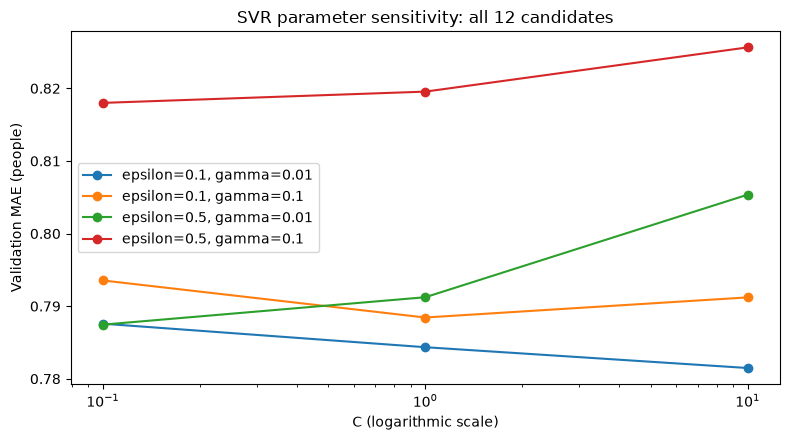

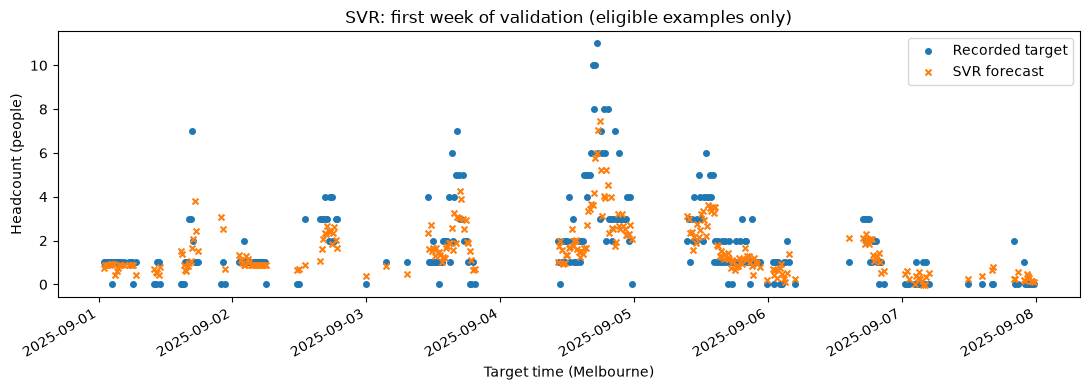

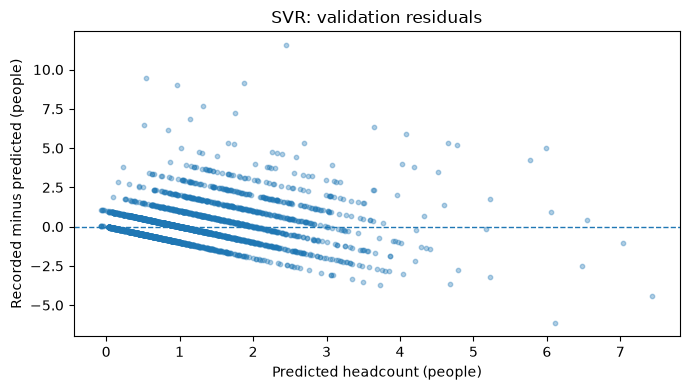

In [10]:
sensitivity_fig, ax = plt.subplots(figsize=(8, 4.5))
for epsilon in epsilon_values:
    for gamma in gamma_values:
        subset = search_results[(search_results["epsilon"] == epsilon) &
                                (search_results["gamma"] == gamma)].sort_values("C")
        ax.plot(subset["C"], subset["validation_mae_people"], marker="o",
                label=f"epsilon={epsilon}, gamma={gamma}")
ax.set_xscale("log")
ax.set_xlabel("C (logarithmic scale)")
ax.set_ylabel("Validation MAE (people)")
ax.set_title("SVR parameter sensitivity: all 12 candidates")
ax.legend()
sensitivity_fig.tight_layout()
plt.show()

week_start = pd.Timestamp(settings["validation_start"])
week_end = week_start + pd.Timedelta(days=7)
plot_data = validation_predictions[(validation_predictions["target_time"] >= week_start) &
                                   (validation_predictions["target_time"] < week_end)]
plot_times = plot_data["target_time"].dt.tz_convert("Australia/Melbourne")
week_fig, ax = plt.subplots(figsize=(11, 4))
ax.scatter(plot_times, plot_data["observed_headcount"], s=16, label="Recorded target")
ax.scatter(plot_times, plot_data["predicted_headcount"], s=18, marker="x", label="SVR forecast")
ax.set_title("SVR: first week of validation (eligible examples only)")
ax.set_xlabel("Target time (Melbourne)")
ax.set_ylabel("Headcount (people)")
ax.legend()
week_fig.autofmt_xdate()
week_fig.tight_layout()
plt.show()

residual_fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(validation_predictions["predicted_headcount"],
           validation_predictions["residual_people"], s=10, alpha=0.35)
ax.axhline(0, linestyle="--", linewidth=1)
ax.set_title("SVR: validation residuals")
ax.set_xlabel("Predicted headcount (people)")
ax.set_ylabel("Recorded minus predicted (people)")
residual_fig.tight_layout()
plt.show()

### Save reproducible results for Comparison

In [11]:
output_folder = project_root / "outputs" / space_prefix / "svr"
output_folder.mkdir(parents=True, exist_ok=True)
metrics.to_csv(output_folder / "metrics.csv", index=False)
comparison.to_csv(output_folder / "comparison_with_reference_models.csv", index=False)
ranked_results.to_csv(output_folder / "tuning_results.csv", index=False)
quality_summary.to_csv(output_folder / "prediction_checks.csv", index=False)
range_summary.to_csv(output_folder / "validation_input_ranges.csv", index=False)
monthly_metrics.to_csv(output_folder / "validation_monthly_metrics.csv", index=False)
scaling_summary.to_csv(output_folder / "scaling.csv", index=False)
timing.to_csv(output_folder / "timing.csv", index=False)
for name, predictions in predictions_by_split.items():
    predictions.to_csv(output_folder / f"{name}_predictions.csv", index=False)
sensitivity_fig.savefig(output_folder / "parameter_sensitivity.png", dpi=160, bbox_inches="tight")
week_fig.savefig(output_folder / "validation_first_week.png", dpi=160, bbox_inches="tight")
residual_fig.savefig(output_folder / "validation_residuals.png", dpi=160, bbox_inches="tight")
(output_folder / "prediction_profile.txt").write_text(profile_text, encoding="utf-8")
joblib.dump(model, output_folder / "model.joblib")

with open(output_folder / "selected_settings.json", "w", encoding="utf-8") as file:
    json.dump(selected_parameters, file, indent=2)

run_information = {
    "model": "svr",
    "estimator": "StandardScaler followed by sklearn.svm.SVR(kernel='rbf')",
    "estimator_parameters": model.named_steps["svr"].get_params(),
    "initial_parameters": initial_parameters,
    "selected_parameters": selected_parameters,
    "selected_candidate_id": best_id,
    "search_candidates": candidates,
    "selection_rule": "minimum validation MAE; exact ties use RMSE then candidate_id",
    "training_objective": "epsilon-insensitive SVR loss with regularisation; target stays in people",
    "fit_partitions": ["train"],
    "selection_partition": "validation",
    "evaluated_partitions": list(datasets),
    "test_data_used": False,
    "space_id": settings["space_id"],
    "horizon_minutes": settings["horizon_minutes"],
    "input_columns": feature_columns,
    "encoded_columns": list(X_train.columns),
    "encoding": "unchanged from Notebook 4: counts, daily sin/cos, Tue-Sun flags",
    "scaling": "StandardScaler on every encoded column; fitted on training only; target unscaled",
    "scaler_training_samples": int(scaler.n_samples_seen_),
    "scaler_means": scaler.mean_.tolist(),
    "scaler_scales": scaler.scale_.tolist(),
    "output_policy": "raw fractional predictions; no rounding or clipping",
    "csv_sha256": fingerprints,
    "encoding_source_sha256": hashlib.sha256((project_root / "src" / "features.py").read_bytes()).hexdigest(),
    "svr_source_sha256": hashlib.sha256((project_root / "src" / "svr_model.py").read_bytes()).hexdigest(),
    "metrics_source_sha256": hashlib.sha256((project_root / "src" / "evaluation.py").read_bytes()).hexdigest(),
    "preparation_settings": settings,
    "python_version": platform.python_version(),
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "scikit_learn_version": sklearn.__version__,
    "joblib_version": joblib.__version__,
    "fit_seconds": float(best_row["fit_seconds"]),
    "parameter_search_seconds": search_seconds,
    "reference_linear_fit_seconds": linear_fit_seconds,
    "timing_scope": "trained scaling plus prediction on encoded validation table; encoding-plus-predict separate; IO excluded",
    "model_file": "model.joblib; training-only fit; load only trusted local files"
}
with open(output_folder / "run_information.json", "w", encoding="utf-8") as file:
    json.dump(run_information, file, indent=2)
print("Saved SVR results to:", output_folder)
print("The final-test CSV has not been opened or scored.")

Saved SVR results to: C:\Users\chris\OneDrive\Desktop\MMA3001\Project\mma3001_project\outputs\227f1068\svr
The final-test CSV has not been opened or scored.
